# Setup

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from src.constants import DATASETS_DIR
from src.data_loading import load_csv_data, parse_preprocessing_config
from src.dataset_config import load_dataset_config
from src.preprocessing import filter_doublets, normalize_by_library_size, log_transform, normalize_with_pearson
from src.preprocessing.gene_annotation import load_gene_annotation
from src.preprocessing.gene_sets import duplicated_genes, matching_genes, rrna_genes, unmatched_genes
from src.preprocessing.pipeline import run_filtering_pipeline
from src.preprocessing.qc_metrics import cell_qc_metrics
from src.visualization import (
    plot_qc_overview,
    plot_gene_set_qc,
    plot_gene_max_count_distribution,
    plot_normalization_comparison,
    plot_log_transform_comparison,
)

## Data Loading

In [3]:
from src.data_loading import load_csv_data

DATA_PATH = DATASETS_DIR / 'GSE118767_dropseq_3cl' / 'interim' / 'counts.csv.gz'
raw_data = load_csv_data(DATA_PATH)

raw_data

,ENSG00000248925,ENSG00000199201,ENSG00000207983,ENSG00000252625,ENSG00000224967,ENSG00000206682,ENSG00000239356,ENSG00000272435,ENSG00000270816,ENSG00000062524,...,ENSG00000258539,ENSG00000270040,ENSG00000172572,ENSG00000146674,ENSG00000207417,ENSG00000257287,ENSG00000135374,ENSG00000261442,ENSG00000259215,ENSG00000217482
cell_id,,,,,,,,,,,,,,,,,,,,,
CELL_000001,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
CELL_000002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,9,0,0,0,0,0,0
CELL_000003,0,0,0,0,0,0,0,0,0,0,...,0,0,0,6,0,0,0,0,0,0
CELL_000004,0,0,0,0,0,0,0,0,0,0,...,0,0,0,2,0,0,0,0,0,0
CELL_000005,0,0,0,0,0,0,0,0,0,0,...,0,0,0,6,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CELL_000237,0,0,0,0,0,0,0,0,0,0,...,0,0,0,2,0,0,0,0,0,0
CELL_000238,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CELL_000246,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Dataset config

In [4]:
DATASET_DIR = DATASETS_DIR / 'GSE118767_dropseq_3cl'

dataset_config = load_dataset_config(DATASET_DIR / 'config.yaml')
SPECIES = dataset_config["species"]
preprocessing_config = parse_preprocessing_config(dataset_config)

preprocessing_config

PreprocessingConfig(mito_threshold=0.2, min_gene_max_count=2, count_threshold=None, gene_threshold=None)

# Quality Control

In [5]:
qc_metrics = cell_qc_metrics(raw_data, species=SPECIES)

print(qc_metrics.median().round(3))
display(qc_metrics.head(5).round(3))
display(qc_metrics.tail(5).round(3))

count_depth           23182.000
n_genes                5800.500
mito_fraction             0.038
rrna_fraction             0.019
apoptosis_fraction        0.017
dtype: float64


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
CELL_000003,80134,9650,0.032,0.017,0.016
CELL_000004,74611,9257,0.022,0.011,0.017
CELL_000001,74261,9284,0.032,0.019,0.016
CELL_000002,68421,9255,0.037,0.019,0.019
CELL_000005,66161,9125,0.030,0.018,0.016


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
CELL_000217,10914,4108,0.029,0.014,0.021
CELL_000225,10599,4178,0.033,0.027,0.016
CELL_000208,10220,3977,0.043,0.023,0.019
CELL_000230,9583,3968,0.042,0.032,0.017
CELL_000302,8557,3194,0.047,0.020,0.020


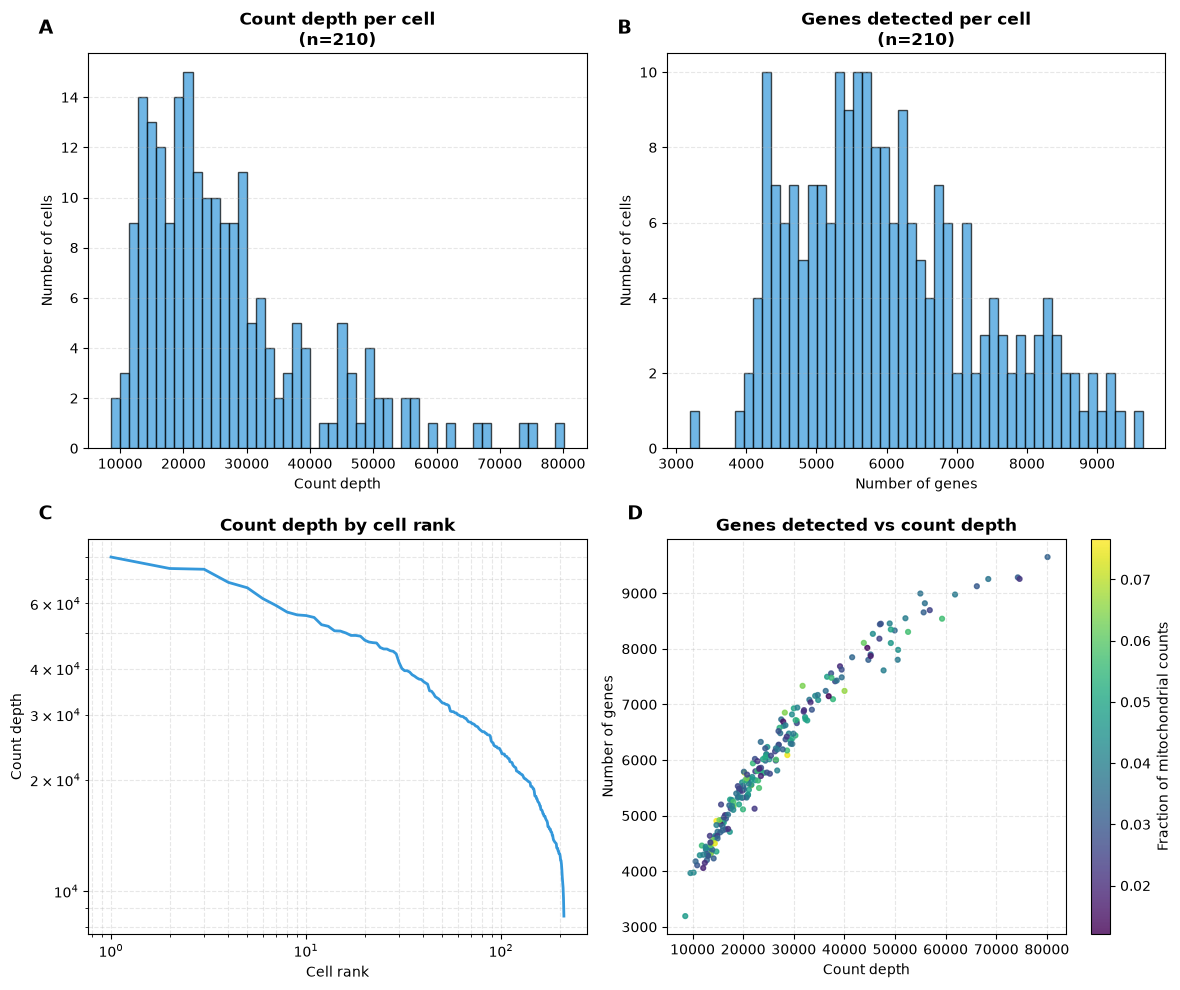

In [6]:
plot_qc_overview(
    raw_data,
    species=SPECIES,
    count_threshold=preprocessing_config.count_threshold,  # minimum count depth, set in the dataset config
    gene_threshold=preprocessing_config.gene_threshold,    # minimum genes per cell, set in the dataset config
)

## Mitochondrial, rRNA and apoptosis fractions

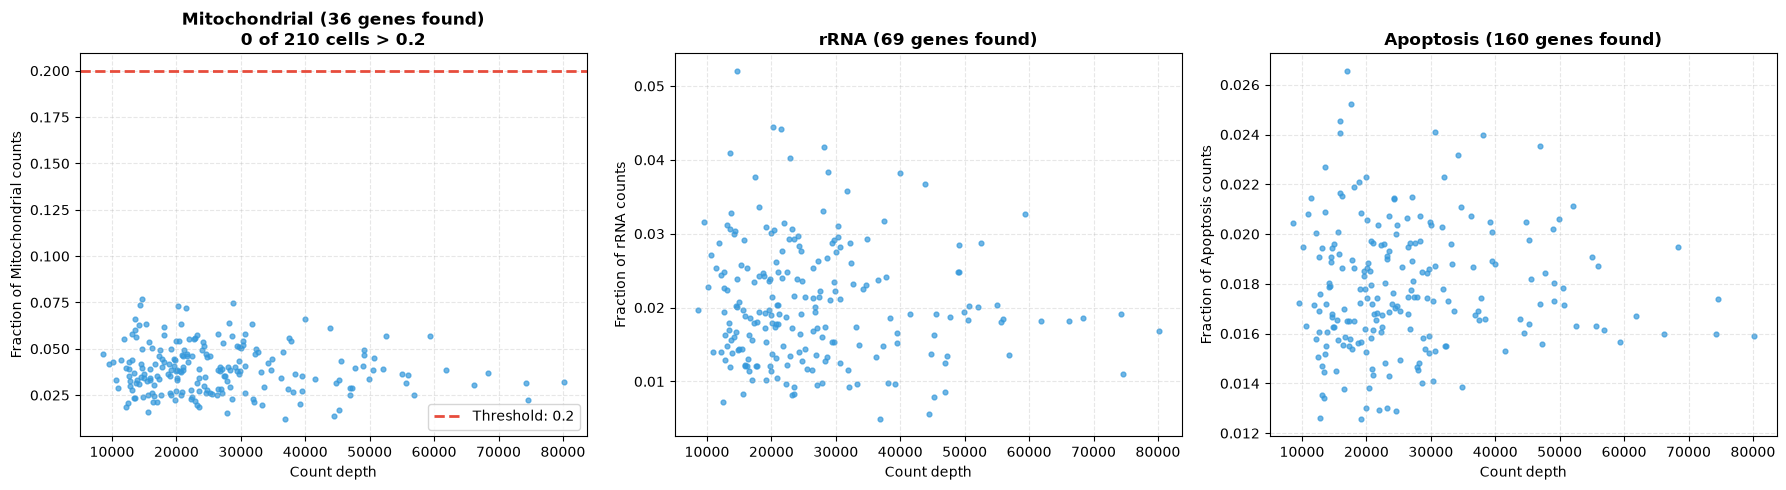

In [7]:
plot_gene_set_qc(raw_data, SPECIES, preprocessing_config)

## Genes

### Uniqueness

In [8]:
duplicates = duplicated_genes(raw_data)

print(f"Gene columns: {raw_data.shape[1]}, unique gene names: {raw_data.columns.nunique()}")
print(f"Gene names appearing in more than one column: {len(duplicates)}")
display(duplicates)

assert duplicates.empty, "Duplicated gene names found, see the table above"

Gene columns: 31253, unique gene names: 31253
Gene names appearing in more than one column: 0


,n_columns,identical_counts
gene,,


### Missing from the annotation

In [9]:
annotation = load_gene_annotation(SPECIES)
unmatched = unmatched_genes(raw_data, annotation)
alias_hits = unmatched.alias_matches
n_alias_genes = alias_hits["gene"].nunique()
n_ambiguous = alias_hits.loc[alias_hits["n_matches"] > 1, "gene"].nunique()

print(f"Genes matching no gene_id or gene_name: {n_alias_genes + len(unmatched.unknown_ensembl_ids) + len(unmatched.other)} / {raw_data.shape[1]}")
print(f"  found through alias_names: {n_alias_genes} ({n_ambiguous} matching more than one annotation row)")
print(f"  Ensembl IDs missing from the annotation: {len(unmatched.unknown_ensembl_ids)}, e.g. {unmatched.unknown_ensembl_ids[:5]}")
print(f"  other: {len(unmatched.other)}, e.g. {unmatched.other[:5]}")
display(alias_hits)

Genes matching no gene_id or gene_name: 642 / 31253
  found through alias_names: 0 (0 matching more than one annotation row)
  Ensembl IDs missing from the annotation: 642, e.g. ['ENSG00000274911', 'ENSG00000230641', 'ENSG00000258137', 'ENSG00000203886', 'ENSG00000237422']
  other: 0, e.g. []


,gene,n_matches,gene_id,gene_name,gene_biotype,chromosome,MT_status,RB_status,TF_status,APOPT_status,alias_names


### rRNA

In [10]:
# Same matching as filter_rrna_genes, so these are exactly the columns the pipeline drops
rrna_columns = matching_genes(raw_data, rrna_genes(SPECIES, annotation))
rrna_counts = raw_data[rrna_columns].sum().sort_values(ascending=False).rename("total_counts")

print(f"rRNA genes filtered out: {len(rrna_columns)} / {raw_data.shape[1]}")
print(f"  share of all counts: {rrna_counts.sum() / raw_data.values.sum():.3f}")
display(rrna_counts.to_frame())

rRNA genes filtered out: 69 / 31253
  share of all counts: 0.020


,total_counts
ENSG00000210082,106357
ENSG00000211459,7309
ENSG00000223138,2
ENSG00000252546,2
ENSG00000202056,2
...,...
ENSG00000200225,0
ENSG00000222920,0
ENSG00000252246,0
ENSG00000251978,0


## Filtering pipeline

In [11]:
clean_data = run_filtering_pipeline(raw_data, config=preprocessing_config, species=SPECIES)

clean_data.shape

(210, 17305)

### Low expression genes

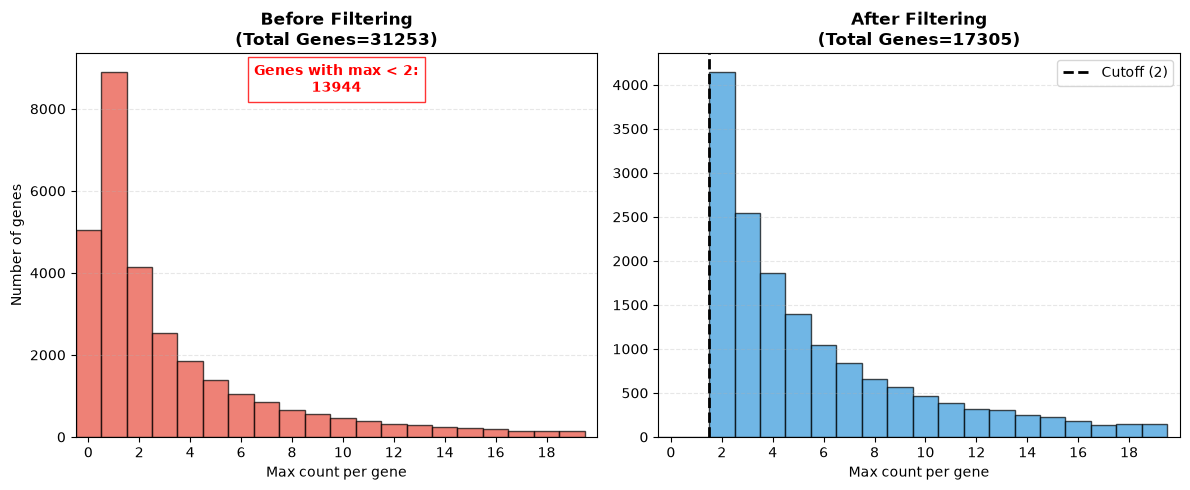

In [12]:
plot_gene_max_count_distribution(raw_data, clean_data, x_limit=20)

## Doublets (demonstration only)

We run the doublet filter to show how many cells it would remove, but the rest of the notebook continues from `clean_data`.

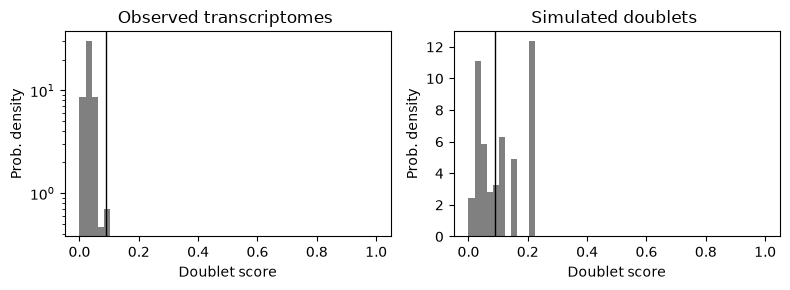

Cells removed as doublets: 0 / 210


In [13]:
# For demonstration only: the rest of the notebook continues from clean_data, not from no_doublets_data
no_doublets_data = filter_doublets(clean_data)

print(f"Cells removed as doublets: {clean_data.shape[0] - no_doublets_data.shape[0]} / {clean_data.shape[0]}")

# Normalization

## logCPM

### Normalize by library size

In [14]:
normalized_data = normalize_by_library_size(clean_data)

normalized_data.shape

(210, 17305)

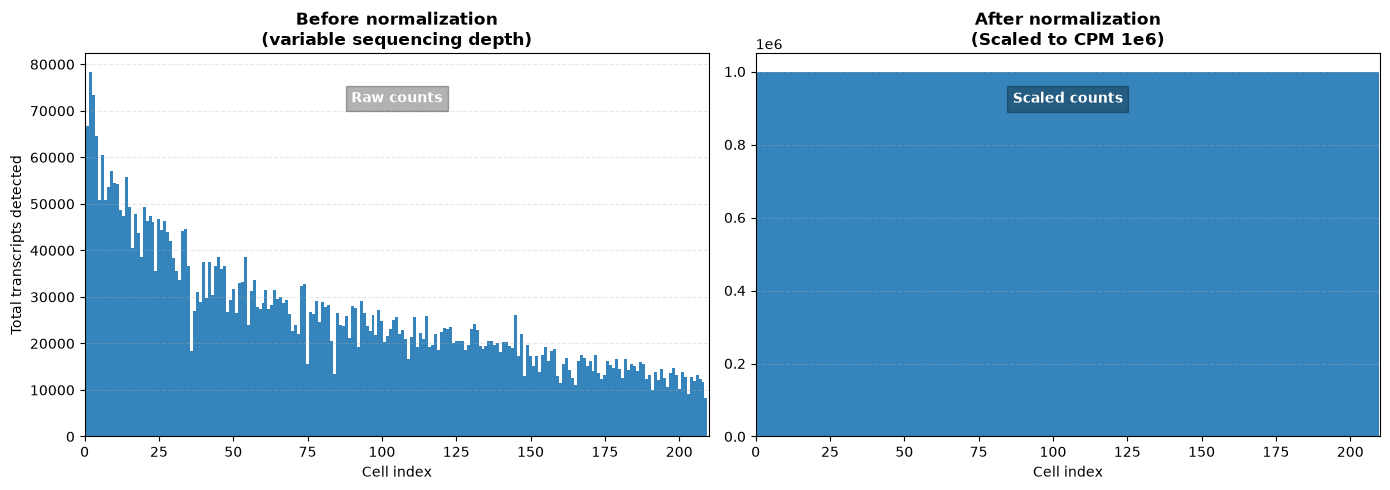

In [15]:
plot_normalization_comparison(clean_data, normalized_data, n_cells=normalized_data.shape[0])

### Log Transform

In [16]:
logged_data = log_transform(normalized_data)

logged_data.shape

(210, 17305)

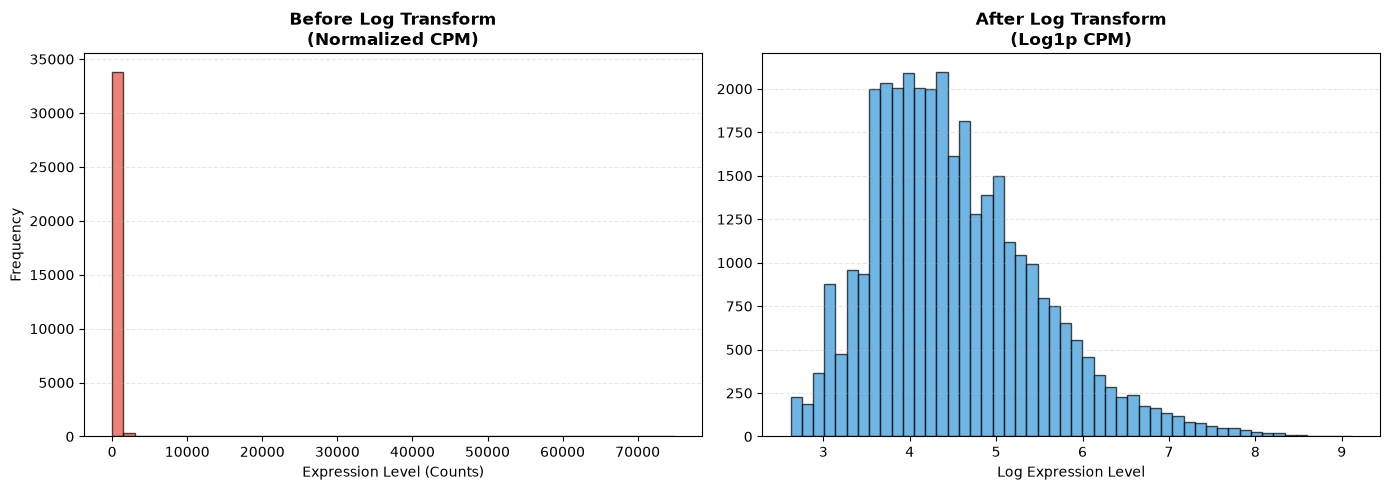

In [17]:
plot_log_transform_comparison(normalized_data, logged_data)

## Pearson residuals

In [18]:
pearsons_data = normalize_with_pearson(clean_data)

pearsons_data.shape

(210, 17305)

In [19]:
pearsons_data.head()

,ENSG00000183048,ENSG00000223849,ENSG00000225355,ENSG00000135093,ENSG00000183579,ENSG00000138363,ENSG00000175061,ENSG00000110697,ENSG00000249541,ENSG00000128564,...,ENSG00000133265,ENSG00000164465,ENSG00000271002,ENSG00000150316,ENSG00000249485,ENSG00000173598,ENSG00000264301,ENSG00000153933,ENSG00000133789,ENSG00000146674
cell_id,,,,,,,,,,,,,,,,,,,,,
CELL_000001,-0.715353,-0.362924,-1.263456,-0.584582,-0.595678,-2.025150,1.524525,-0.472977,-0.444343,-1.248196,...,0.514459,0.430633,0.996610,1.135996,-0.472977,1.043946,-0.458885,0.205375,2.022006,-4.706420
CELL_000002,0.762163,-0.348418,-1.213654,-0.561263,-0.571920,1.116933,-1.179737,-0.454089,-0.426594,-1.198978,...,-0.846843,0.572502,-0.592652,-0.200715,-0.454089,0.387073,-0.440558,-1.251901,1.804160,-3.227104
CELL_000003,-0.744126,-0.377581,-0.565610,-0.608138,-0.619679,2.713558,-0.190760,-0.492060,-0.462276,-1.297843,...,-1.080298,-0.948695,-0.642128,-0.755812,1.535291,0.159791,-0.477402,5.889723,-0.418442,-4.114842
CELL_000004,-0.720427,-0.365509,0.274165,-0.588736,2.721919,0.486315,1.113150,-0.476342,-0.447505,-1.256956,...,-0.985386,-1.520872,-0.621650,-0.303087,-0.476342,1.785269,-0.462151,-1.312354,0.162434,-4.578596
CELL_000005,-0.675974,2.570206,2.931161,4.862408,1.208236,-0.884857,3.247172,-0.446871,1.958011,0.490948,...,-0.277751,-0.742853,-0.583245,-1.569367,-0.446871,2.888014,-0.433554,1.165301,-1.010887,-3.644022
